# R2c — Supervisor con zoom a la zona del choque (ROI) + LoRA

## Por qué R2b no funcionó

En R2b el modelo veía la **imagen completa reducida** (~518×291). En CCTV lejana un auto mide 5–15 píxeles, así que el choque prácticamente no se veía. El modelo aprendió un atajo: "si es un cruce digo choque en T, si es autopista digo choque de un solo vehículo". Las falsas alarmas se quedaron en 93 % (base: 97 %).

| R2b (imagen completa, 60 ventanas test) | Sin LoRA | Con LoRA |
|---|---|---|
| Falsas alarmas | 29/30 | 28/30 |
| Choques detectados | 30/30 | 28/30 |
| Tipo correcto | 47 % | 57 % |

## Qué cambia en R2c

1. **Zoom a la región (ROI).** ACCIDENT trae la caja de cada choque. Se recorta un cuadrado de **3 veces** el tamaño de esa caja (mínimo 25 % del lado corto del frame) y se escala a 392×392. **La ventana negativa se recorta en el mismo lugar**: misma zona, solo que antes del choque. En el sistema real, esta zona la marca el tracker (paso 2 de la cascada).
   - **Para el reporte:** esta evaluación supone que el paso 2 ya encontró la zona correcta. Mide qué tan bien el supervisor **confirma o descarta** lo que le marcan.
   - En entrenamiento el recorte se mueve y cambia de tamaño un poco al azar (*jitter*), para que el modelo no aprenda "el choque siempre está exactamente al centro".
2. **Respuesta corta:** `{"incidente", "tipo", "segundo_aprox"}`, con `incidente` primero. Se quitó la descripción de plantilla, que solo enseñaba el atajo del lugar. En el sistema final, `camara_fija` es fija (C5) y la descripción se arma con el tipo.
3. **Probabilidad de "sí".** Además de leer la respuesta, se mide **P(incidente = true)** directo de la salida del modelo. Con eso se calcula el **AUC**: qué tan bien *ordena* los casos, de 0.5 (azar) a 1.0 (perfecto). El **umbral** se elige con validación, nunca con test.
4. **Validación con AUC**, no con la pérdida promedio. En R2b la pérdida bajó a 0.06 y engañaba: de ~51 tokens solo uno (`true`/`false`) decide todo.
5. **El LoRA también toca el *merger*,** la capa que traduce lo que ve la parte visual al lenguaje. El resto de la visión sigue congelado.

Los videos de train/val/test son **los mismos que R2b** (misma semilla), así que la comparación R2b → R2c es directa.

**Tiempo en T4:** ZIP ~5 min · frames ~15 min · entrenamiento ~45 min · evaluación ~20 min. Usa `USAR_DRIVE = True`.

## 0. Instalación

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes peft huggingface_hub opencv-python-headless pandas matplotlib scikit-learn "kaggle>=1.7"

In [ ]:
import os, re, json, time, glob, zipfile, random, shutil, subprocess, io, math
from concurrent.futures import ThreadPoolExecutor
import torch
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} · {p.total_memory/1e9:.1f} GB · compute {p.major}.{p.minor}")

USAR_DRIVE = True        # recomendado: checkpoints y resultados sobreviven a una desconexión

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_PERSISTENTE = "/content/drive/MyDrive/roadvision"
else:
    DIR_PERSISTENTE = "/content/datos_roadvision"
DIR_LOCAL = "/content/datos_roadvision"                   # videos y frames: disco local (rápido)
DIR_ACC = os.path.join(DIR_LOCAL, "accident")
DIR_MUESTRAS = DIR_ACC
DIR_CLIPS = os.path.join(DIR_LOCAL, "clips_eval_roi")      # frames de val/test (recortados)
DIR_CLIPS_TRAIN = os.path.join(DIR_LOCAL, "clips_train_roi")   # frames de train (recortados)
DIR_RESULTADOS = os.path.join(DIR_PERSISTENTE, "resultados_qwen")
DIR_LORA = os.path.join(DIR_PERSISTENTE, "lora_supervisor_roi")
for d in (DIR_ACC, DIR_CLIPS, DIR_CLIPS_TRAIN, DIR_RESULTADOS, DIR_LORA):
    os.makedirs(d, exist_ok=True)
EXT_VIDEO = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
SEMILLA = 0
rng = random.Random(SEMILLA)
print("Persistente:", DIR_PERSISTENTE)

GPU: Tesla T4 · 15.6 GB · compute 7.5
Mounted at /content/drive
Persistente: /content/drive/MyDrive/roadvision


## 1. Kaggle: tablas de ACCIDENT

In [ ]:
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
DATASET = "picekl/accident"


def kaggle(*args, timeout=300):
    try:
        r = subprocess.run(["kaggle", *args], capture_output=True, text=True, timeout=timeout,
                           stdin=subprocess.DEVNULL)
    except subprocess.TimeoutExpired:
        raise RuntimeError(f"kaggle {' '.join(args[:3])} tardó más de {timeout} s")
    if r.returncode != 0:
        raise RuntimeError(r.stderr or r.stdout)
    return r.stdout


def bajar(nombre):
    """Baja un archivo del dataset a DIR_ACC/nombre (si no está). Devuelve (nombre, ok)."""
    destino = os.path.join(DIR_ACC, nombre)
    if os.path.exists(destino):
        return nombre, True
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    for intento in range(3):
        try:
            kaggle("datasets", "download", DATASET, "-f", nombre, "-p", os.path.dirname(destino))
            z = destino + ".zip"
            if os.path.exists(z):
                with zipfile.ZipFile(z) as zz:
                    zz.extractall(os.path.dirname(destino))
                os.remove(z)
            return nombre, os.path.exists(destino)
        except RuntimeError:
            time.sleep(2 * (intento + 1))
    return nombre, False


def bajar_varios(nombres, hilos=8):
    nombres = list(dict.fromkeys(nombres))
    t0, hechos, fallos = time.time(), 0, []
    with ThreadPoolExecutor(hilos) as ex:
        for nombre, ok in ex.map(bajar, nombres):
            hechos += 1
            if not ok:
                fallos.append(nombre)
            if hechos % 25 == 0 or hechos == len(nombres):
                print(f"  {hechos}/{len(nombres)} · {time.time()-t0:.0f} s", flush=True)
    if fallos:
        print(f"⚠️  {len(fallos)} no se pudieron bajar (se ignoran):", fallos[:5])
    return [n for n in nombres if n not in fallos]


print("Probando sesión de Kaggle...", end=" ", flush=True)
kaggle("datasets", "list", "-s", "accident", timeout=60)
print("OK")
for t in ("metadata-real.csv", "metadata-synthetic.csv"):
    bajar(t)
real = pd.read_csv(os.path.join(DIR_ACC, "metadata-real.csv"))
sint = pd.read_csv(os.path.join(DIR_ACC, "metadata-synthetic.csv"))
print("real:", real.shape, real["split_in_distribution"].value_counts().to_dict())
print("sintético:", sint.shape)

Probando sesión de Kaggle... OK
real: (2027, 22) {'test': 1520, 'train': 507}
sintético: (2211, 19)


## 2. Ventanas positivas y negativas (mismas que R2b) + región del choque

Igual que R2b, pero cada ventana guarda la **caja del choque** `(centro_x, centro_y, ancho, alto)` en coordenadas normalizadas (0–1). Las llamadas al generador aleatorio son idénticas a R2b, así que salen exactamente las mismas ventanas.

In [ ]:
VENTANA_S, MARGEN_S, MIN_NEG_S = 8.0, 3.0, 4.0
T_MIN_NEG = MARGEN_S + MIN_NEG_S
N_SINTETICOS = 300
FRAC_VAL = 0.10
MAX_EJEMPLOS = 800
MIN_NEG_TEST = 30


def roi_de(f):
    """Caja del choque normalizada (cx, cy, ancho, alto); None si faltan datos."""
    try:
        x1, y1, x2, y2 = (float(f[k]) for k in ("x1", "y1", "x2", "y2"))
        cx, cy = float(f["center_x"]), float(f["center_y"])
    except (KeyError, TypeError, ValueError):
        return None
    if any(np.isnan([x1, y1, x2, y2, cx, cy])):
        return None
    return (cx, cy, max(x2 - x1, 0.01), max(y2 - y1, 0.01))


def ventanas_de(video_id, ruta_rel, t, dur, tipo, contexto, dominio, r, n_neg=1, roi=None):
    out = []
    antes = r.uniform(1.5, VENTANA_S - 1.5)
    ini = max(0.0, min(t - antes, dur - VENTANA_S))
    out.append({"clase": "positiva", "inicio": ini, "fin": min(dur, ini + VENTANA_S), "t_rel": t - ini})
    fin_max = t - MARGEN_S
    for _ in range(n_neg):
        if fin_max < MIN_NEG_S:
            break
        largo = min(VENTANA_S, fin_max)
        fin = r.uniform(max(largo, fin_max - 4.0), fin_max)
        out.append({"clase": "negativa", "inicio": max(0.0, fin - largo), "fin": fin, "t_rel": None})
    for v in out:
        v.update({"video": video_id, "ruta_rel": ruta_rel, "t_choque": t, "tipo_real": tipo,
                  "contexto": contexto, "dominio": dominio, "roi": roi})
    return out


def contexto_real(f):
    return {"lugar": f.get("scene_layout"), "hora": f.get("day_time"), "clima": f.get("weather")}


def contexto_sint(f):
    return {"lugar": None, "hora": "night" if "night" in str(f.get("weather")) else "day", "clima": f.get("weather")}


tr = real[real["split_in_distribution"] == "train"].copy()
tr["video"] = tr["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
videos_tr = sorted(tr["video"].unique())
rng.shuffle(videos_tr)
n_val = max(5, int(len(videos_tr) * FRAC_VAL))
VIDEOS_VAL = set(videos_tr[:n_val])
tr["grupo"] = np.where(tr["video"].isin(VIDEOS_VAL), "val", "train")

por_tipo = N_SINTETICOS // sint["type"].nunique()
si = sint.sample(frac=1, random_state=SEMILLA).groupby("type").head(por_tipo).copy()
si["video"] = si["rgb_path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])

candidatas = []
for _, f in tr.iterrows():
    for v in ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                         contexto_real(f), "real", rng, n_neg=2, roi=roi_de(f)):
        v["grupo"] = f["grupo"]; candidatas.append(v)
for _, f in si.iterrows():
    for v in ventanas_de(f["video"], f["rgb_path"], f["accident_time"], f["duration"], f["type"],
                         contexto_sint(f), "sintetico", rng, n_neg=2, roi=roi_de(f)):
        v["grupo"] = "train"; candidatas.append(v)
CAND = pd.DataFrame(candidatas)
print(CAND.groupby(["grupo", "dominio", "clase"]).size().unstack(fill_value=0))
print("Ventanas sin caja del choque (se usa el frame completo):", int(CAND["roi"].isna().sum()))

mitad = MAX_EJEMPLOS // 2
tr_c = CAND[CAND["grupo"] == "train"]
neg = tr_c[tr_c["clase"] == "negativa"]
neg = neg.sample(mitad, replace=len(neg) < mitad, random_state=SEMILLA)
pos = tr_c[tr_c["clase"] == "positiva"]
pos = pos.sample(frac=1, random_state=SEMILLA).groupby("dominio").head(mitad // 2)
pos = pd.concat([pos, tr_c[(tr_c["clase"] == "positiva") & ~tr_c.index.isin(pos.index)].sample(
    max(0, mitad - len(pos)), random_state=SEMILLA)])
TRAIN = pd.concat([pos, neg]).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
VAL = CAND[CAND["grupo"] == "val"].reset_index(drop=True)

# Test: mismo procedimiento y semilla que R2b (sin CSV de R2a)
te = real[real["split_in_distribution"] == "test"].copy()
te["video"] = te["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
extra = te[te["accident_time"] >= T_MIN_NEG].sample(frac=1, random_state=SEMILLA)
r_test, filas_test = random.Random(SEMILLA + 1), []
for _, f in extra.iterrows():
    if sum(x["clase"] == "negativa" for x in filas_test) >= MIN_NEG_TEST:
        break
    filas_test += ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                              contexto_real(f), "real", r_test, n_neg=1, roi=roi_de(f))
TEST = pd.DataFrame(filas_test)
assert not (set(TEST["video"]) & (set(TRAIN["video"]) | set(VAL["video"]))), "¡Fuga test↔train!"
for nombre, df in (("TRAIN", TRAIN), ("VAL", VAL), ("TEST", TEST)):
    print(f"{nombre}: {len(df)} ventanas · {df['clase'].value_counts().to_dict()}")

clase            negativa  positiva
grupo dominio                      
train real            186       457
      sintetico       270       300
val   real             14        50
Ventanas sin caja del choque (se usa el frame completo): 0
TRAIN: 800 ventanas · {'positiva': 400, 'negativa': 400}
VAL: 64 ventanas · {'positiva': 50, 'negativa': 14}
TEST: 60 ventanas · {'positiva': 30, 'negativa': 30}


## 3. Dataset completo (ZIP) y extracción de los videos necesarios

In [ ]:
libre_gb = shutil.disk_usage("/content").free / 1e9
print(f"Disco libre: {libre_gb:.0f} GB")
assert libre_gb > 30, "Hacen falta ~30 GB libres (20 del ZIP + videos extraídos + frames)"

ZIP = next(iter(glob.glob(os.path.join(DIR_LOCAL, "*.zip"))), None)
if ZIP is not None and not zipfile.is_zipfile(ZIP):
    print("ZIP incompleto de una sesión anterior: se borra y se baja de nuevo")
    os.remove(ZIP); ZIP = None
if ZIP is None:
    t0 = time.time()
    !kaggle datasets download {DATASET} -p {DIR_LOCAL}
    ZIP = glob.glob(os.path.join(DIR_LOCAL, "*.zip"))[0]
    print(f"Descargado en {(time.time()-t0)/60:.1f} min")
zf = zipfile.ZipFile(ZIP)
miembros = set(zf.namelist())
print(f"ZIP: {os.path.getsize(ZIP)/1e9:.1f} GB · {len(miembros)} archivos")

Disco libre: 120 GB
Dataset URL: https://www.kaggle.com/datasets/picekl/accident
License(s): CC-BY-NC-SA-4.0
100% 15.6G/15.6G [03:44<00:00, 74.7MB/s]

Descargado en 3.8 min
ZIP: 16.8 GB · 6452 archivos


In [ ]:
necesarios = sorted(set(TRAIN["ruta_rel"]) | set(VAL["ruta_rel"]) | set(TEST["ruta_rel"]))
faltan_zip = [n for n in necesarios if n not in miembros]
if faltan_zip:
    print(f"⚠️  {len(faltan_zip)} rutas no están en el ZIP, ej.: {faltan_zip[:3]}")
t0 = time.time()
for k, n in enumerate(necesarios, 1):
    if n in miembros and not os.path.exists(os.path.join(DIR_ACC, n)):
        zf.extract(n, DIR_ACC)
    if k % 100 == 0:
        print(f"  {k}/{len(necesarios)} · {time.time()-t0:.0f} s", flush=True)
ok = {n for n in necesarios if os.path.exists(os.path.join(DIR_ACC, n))}
print(f"{len(ok)}/{len(necesarios)} videos listos · {time.time()-t0:.0f} s")
for nombre, df in (("TRAIN", TRAIN), ("VAL", VAL), ("TEST", TEST)):
    antes = len(df)
    df.drop(df[~df["ruta_rel"].isin(ok)].index, inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"{nombre}: {len(df)}/{antes} ventanas con video")
assert len(TRAIN) > 0.9 * MAX_EJEMPLOS, "Faltan demasiados videos: no entrenes así, revisa el aviso de arriba"
for df in (TRAIN, VAL, TEST):
    df["ruta"] = df["ruta_rel"].map(lambda n: os.path.join(DIR_ACC, n))

  100/575 · 1 s
  200/575 · 5 s
  300/575 · 7 s
  400/575 · 12 s
  500/575 · 20 s
575/575 videos listos · 23 s
TRAIN: 800/800 ventanas con video
VAL: 64/64 ventanas con video
TEST: 60/60 ventanas con video


## 4. Frames recortados a la región del choque

`ZOOM = 3`: el cuadrado mide 3 veces el lado mayor de la caja del choque, para incluir a los vehículos que se acercan y no solo el punto del impacto. Si la caja es muy chica, se usa como mínimo el 25 % del lado corto del frame.

El *jitter* (solo en train) mueve el centro hasta ±15 % del lado y cambia el tamaño entre ×0.8 y ×1.25. En val y test **no** hay jitter: el recorte es siempre el mismo.

In [ ]:
def info_video(ruta_video):
    cap = cv2.VideoCapture(ruta_video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return fps, total, (total / fps if fps > 0 else 0), ancho, alto


FPS_VIDEO = 2.0
MAX_FRAMES = 16
MAX_PIXELES_VIDEO = 360 * 420

TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}
MAPEO_TIPO = {   # clase de ACCIDENT (inglés) → clase del JSON
    "head-on": "frontal", "head_on": "frontal", "headon": "frontal",
    "rear-end": "alcance", "rear_end": "alcance", "rearend": "alcance",
    "t-bone": "en_t", "t_bone": "en_t", "tbone": "en_t",
    "sideswipe": "roce_lateral", "side-swipe": "roce_lateral",
    "single": "un_vehiculo", "single-vehicle": "un_vehiculo", "single_vehicle": "un_vehiculo",
}


def tipo_json(valor):
    v = str(valor).strip().lower()
    return MAPEO_TIPO.get(v, MAPEO_TIPO.get(v.replace(" ", "-"), "otro"))



ZOOM, MIN_LADO_FRAC, LADO_SALIDA = 3.0, 0.25, 392


def caja_recorte(roi, ancho, alto, jitter=None):
    """(x0, y0, lado) en píxeles del cuadrado a recortar."""
    corto = min(ancho, alto)
    if roi is None:
        return None
    cx, cy, bw, bh = roi
    lado = max(bw * ancho, bh * alto) * ZOOM
    lado = min(max(lado, MIN_LADO_FRAC * corto), corto)
    cxp, cyp = cx * ancho, cy * alto
    if jitter is not None:
        dx, dy, esc = jitter
        lado = min(max(lado * esc, MIN_LADO_FRAC * corto), corto)
        cxp, cyp = cxp + dx * lado, cyp + dy * lado
    x0 = int(min(max(cxp - lado / 2, 0), ancho - lado))
    y0 = int(min(max(cyp - lado / 2, 0), alto - lado))
    return x0, y0, int(lado)


def muestrear_ventana(ruta, inicio, fin, carpeta, roi=None, jitter=None, max_frames=MAX_FRAMES):
    """Lee la ventana en orden, recorta la región y guarda hasta max_frames jpg de LADO_SALIDA×LADO_SALIDA."""
    fps, total, dur, ancho, alto = info_video(ruta)
    largo = fin - inicio
    n = int(min(max_frames, max(2, largo * FPS_VIDEO)))
    n -= n % 2
    tiempos = [inicio + i * largo / n for i in range(n)]
    caja = caja_recorte(roi, ancho, alto, jitter)
    if caja is None:   # sin ROI: frame completo con el mismo presupuesto de píxeles
        escala = min(1.0, (LADO_SALIDA ** 2 / max(1, ancho * alto)) ** 0.5)
        tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))
    shutil.rmtree(carpeta, ignore_errors=True); os.makedirs(carpeta, exist_ok=True)
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, inicio - 0.5) * 1000)
    rutas, k = [], 0
    while k < len(tiempos) and cap.grab():
        t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
        if t + 1e-3 >= tiempos[k]:
            ok, img = cap.retrieve()
            if ok:
                if caja is not None:
                    x0, y0, lado = caja
                    img = cv2.resize(img[y0:y0 + lado, x0:x0 + lado], (LADO_SALIDA, LADO_SALIDA),
                                     interpolation=cv2.INTER_CUBIC if lado < LADO_SALIDA else cv2.INTER_AREA)
                else:
                    img = cv2.resize(img, tam, interpolation=cv2.INTER_AREA)
                r = os.path.join(carpeta, f"{len(rutas):03d}.jpg")
                cv2.imwrite(r, img)
                rutas.append(r)
            k += 1
            while k < len(tiempos) and t + 1e-3 >= tiempos[k]:
                k += 1
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    return rutas, (len(rutas) / largo if largo > 0 else FPS_VIDEO), largo


def preparar_frames(df, carpeta_base, prefijo, con_jitter):
    r_jit = random.Random(SEMILLA + 7)
    rutas, fpss, durs, cajas = [], [], [], []
    t0 = time.time()
    for i, v in df.iterrows():
        carpeta = os.path.join(carpeta_base, f"{prefijo}{i:05d}")
        jit = (r_jit.uniform(-.15, .15), r_jit.uniform(-.15, .15), r_jit.uniform(.8, 1.25)) if con_jitter else None
        hecho = os.path.join(carpeta, "_ok.json")
        if os.path.exists(hecho):
            info = json.load(open(hecho))
        else:
            r, fps_ef, largo = muestrear_ventana(v["ruta"], v["inicio"], v["fin"], carpeta, v["roi"], jit)
            info = {"frames": r, "fps": fps_ef, "dur": largo}
            json.dump(info, open(hecho, "w"))
        rutas.append(info["frames"]); fpss.append(info["fps"]); durs.append(info["dur"])
        if (i + 1) % 100 == 0:
            print(f"  {prefijo}: {i+1}/{len(df)} · {time.time()-t0:.0f} s", flush=True)
    df["frames"], df["fps_ef"], df["dur"] = rutas, fpss, durs
    df.drop(df[df["frames"].map(len) < 2].index, inplace=True)
    df.reset_index(drop=True, inplace=True)


def respuesta_correcta(v):
    if v["clase"] == "positiva":
        r = {"incidente": True, "tipo": tipo_json(v["tipo_real"]), "segundo_aprox": round(float(v["t_rel"]), 1)}
    else:
        r = {"incidente": False, "tipo": "ninguno", "segundo_aprox": None}
    return json.dumps(r, ensure_ascii=False)


preparar_frames(TRAIN, DIR_CLIPS_TRAIN, "tr", con_jitter=True)
preparar_frames(VAL, DIR_CLIPS, "va", con_jitter=False)
preparar_frames(TEST, DIR_CLIPS, "te", con_jitter=False)
for df in (TRAIN, VAL, TEST):
    df["respuesta"] = df.apply(respuesta_correcta, axis=1)
print("Ejemplos:", TRAIN["respuesta"].iloc[0], "|", TRAIN[TRAIN["clase"] == "negativa"]["respuesta"].iloc[0])

  tr: 100/800 · 90 s
  tr: 200/800 · 194 s
  tr: 300/800 · 288 s
  tr: 400/800 · 394 s
  tr: 500/800 · 482 s
  tr: 600/800 · 573 s
  tr: 700/800 · 666 s
  tr: 800/800 · 756 s
Ejemplos: {"incidente": true, "tipo": "alcance", "segundo_aprox": 1.0} | {"incidente": false, "tipo": "ninguno", "segundo_aprox": null}


### Mirar los recortes

Arriba, el último frame de la ventana **negativa**; abajo, el frame más cercano al **choque** en la positiva. Deben verse la misma zona y los vehículos grandes. Si el choque queda fuera del recorte, sube `ZOOM`.

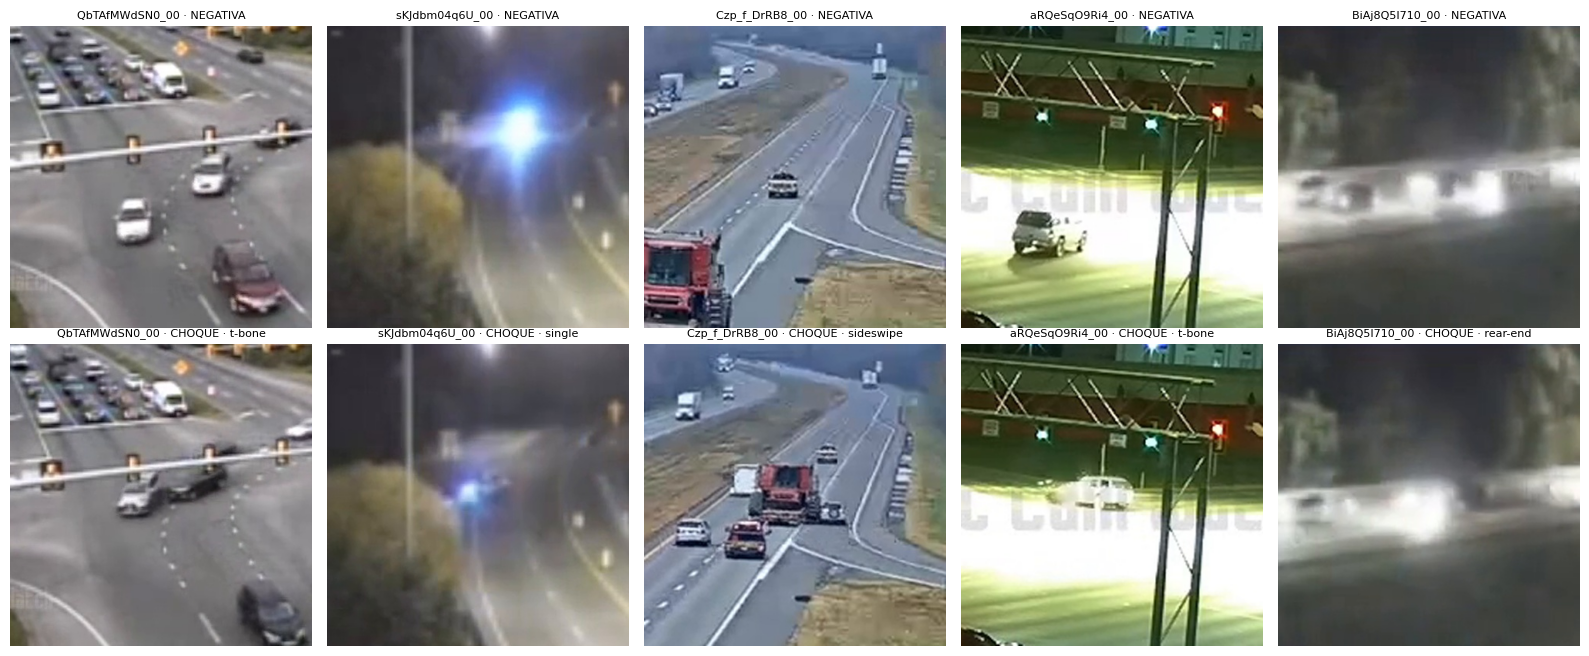

In [ ]:
muestras = TEST.groupby("video").filter(lambda g: set(g["clase"]) == {"positiva", "negativa"})["video"].unique()[:5]
fig, ejes = plt.subplots(2, len(muestras), figsize=(3.2 * len(muestras), 6.6), squeeze=False)
for j, vid in enumerate(muestras):
    g = TEST[TEST["video"] == vid].set_index("clase")
    neg_f = g.loc["negativa", "frames"][-1]
    pos = g.loc["positiva"]
    k = min(len(pos["frames"]) - 1, int(round(pos["t_rel"] * pos["fps_ef"])))
    for i, (ruta, tit) in enumerate([(neg_f, "NEGATIVA"), (pos["frames"][k], f"CHOQUE · {pos['tipo_real']}")]):
        ejes[i, j].imshow(cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB))
        ejes[i, j].set_title(f"{vid[:14]} · {tit}", fontsize=8); ejes[i, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Qwen2.5-VL-3B en 4 bits + LoRA (lenguaje + *merger*)

El *merger* son dos capas lineales (`visual.merger.mlp.0` y `.2`) que convierten lo que extrae la parte visual en "palabras" para la parte de lenguaje. Si el LoRA las toca, el modelo puede aprender a **resaltar** lo que importa (dos vehículos tocándose), no solo a reinterpretarlo. El resto de la visión sigue congelado.

In [ ]:
import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from qwen_vl_utils import process_vision_info

MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MIN_PIX, MAX_PIX = 256 * 28 * 28, 1024 * 28 * 28
print("transformers", transformers.__version__)

cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float16)
t0 = time.time()
modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODELO_ID, quantization_config=cuant, device_map={"": 0}, attn_implementation="sdpa")
try:
    procesador = AutoProcessor.from_pretrained(MODELO_ID, size={"shortest_edge": MIN_PIX, "longest_edge": MAX_PIX})
except (TypeError, ValueError):
    procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=MIN_PIX, max_pixels=MAX_PIX)

modelo = prepare_model_for_kbit_training(modelo, use_gradient_checkpointing=True,
                                         gradient_checkpointing_kwargs={"use_reentrant": False})
OBJETIVOS = (r"^(?!.*visual).*\.(q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)$"
             r"|^.*visual\.merger\.mlp\.(0|2)$")
config_lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                         target_modules=OBJETIVOS, task_type="CAUSAL_LM")

# Huella de los datos de entrenamiento: si cambian (otra semilla, otro MAX_EJEMPLOS), es otro experimento
# y NO se retoma un checkpoint viejo. En la corrida anterior se retomó uno de otros datos por error.
import hashlib
config_exp = {"datos": TRAIN[["video", "clase", "inicio"]].round(3).astype(str).values.tolist(),
              "lr": 2e-4, "r": 16, "acum": 8, "roi": [ZOOM, MIN_LADO_FRAC, LADO_SALIDA], "merger": True}
HUELLA = hashlib.md5(json.dumps(config_exp).encode()).hexdigest()[:8]
DIR_EXP = os.path.join(DIR_LORA, f"exp_{HUELLA}")
os.makedirs(DIR_EXP, exist_ok=True)
print("Experimento:", DIR_EXP)
ultimo = sorted(glob.glob(os.path.join(DIR_EXP, "paso_*")), key=lambda p: int(p.split("_")[-1]))
if ultimo:
    modelo = PeftModel.from_pretrained(modelo, ultimo[-1], is_trainable=True)
    INICIO = int(json.load(open(os.path.join(ultimo[-1], "estado.json")))["ejemplo"])
    print(f"Retomando desde {ultimo[-1]} (ejemplo {INICIO})")
else:
    modelo = get_peft_model(modelo, config_lora)
    INICIO = 0
modelo.print_trainable_parameters()
visual_no_merger = [n for n, p in modelo.named_parameters() if p.requires_grad and "visual" in n and "merger" not in n]
assert not visual_no_merger, f"El LoRA se metió en la visión fuera del merger: {visual_no_merger[:3]}"
print("Capas LoRA en el merger:", sum(1 for n, p in modelo.named_parameters() if p.requires_grad and "merger" in n))
print(f"Cargado en {time.time()-t0:.0f} s · VRAM {torch.cuda.memory_allocated()/1e9:.1f} GB")

transformers 5.22.0


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Experimento: /content/drive/MyDrive/roadvision/lora_supervisor_roi/exp_ebfa594f
Retomando desde /content/drive/MyDrive/roadvision/lora_supervisor_roi/exp_ebfa594f/paso_200 (ejemplo 200)
trainable params: 30,212,096 || all params: 3,784,835,072 || trainable%: 0.7982
Capas LoRA en el merger: 4
Cargado en 143 s · VRAM 3.2 GB


### Funciones de apoyo y prompt nuevo

In [ ]:
from qwen_vl_utils import process_vision_info

_CAP_OK = True   # se apaga solo si esta versión de transformers no reconoce cap_pixels_per_frame


def preguntar(contenido, max_new_tokens=256, fps_video=None):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    global _CAP_OK
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps_video is not None:          # cuando mandamos frames sueltos, el fps real lo sabemos nosotros
            fps = fps_video
        if fps is not None:
            extra["fps"] = float(fps)
        if _CAP_OK:
            extra["cap_pixels_per_frame"] = True

    try:
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    except TypeError:
        _CAP_OK = False
        extra.pop("cap_pixels_per_frame", None)
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    entradas = entradas.to(modelo.device)

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def _primer_json(t):
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None


def _reparar_lineas(t):
    """Pone comillas a valores que no son JSON válido: "clave": 2011-07-04 09:51:13,  ->  "clave": "2011-07-04 09:51:13","""
    salida = []
    for linea in t.splitlines():
        m = re.match(r'^(\s*"[^"]+"\s*:\s*)(.+?)(\s*,?\s*)$', linea)
        if m:
            valor = m.group(2)
            try:
                json.loads(valor)
            except json.JSONDecodeError:
                valor = json.dumps(valor.strip().strip('"'), ensure_ascii=False)
            linea = m.group(1) + valor + m.group(3)
        salida.append(linea)
    return "\n".join(salida)


def extraer_json(texto):
    """Devuelve (objeto_o_None, reparado: bool)."""
    t = re.sub(r"```(?:json)?", "", texto)
    obj = _primer_json(t)
    if obj is not None:
        return obj, False
    obj = _primer_json(_reparar_lineas(t))
    return obj, obj is not None


TIPOS = {"choque_vehiculos", "atropello", "moto_caida", "vehiculo_detenido", "otro", "ninguno"}
FRASES_PLANTILLA = {"una oración en español", "una oracion en español", ""}


def _a_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str) and x.strip().lower() in ("true", "false", "sí", "si", "no"):
        return x.strip().lower() in ("true", "sí", "si")
    return None


def normalizar_juicio(datos, duracion_s):
    """Valida campos y anota qué estaba mal. Devuelve un dict limpio."""
    problemas = []
    inc = _a_bool(datos.get("incidente"))
    if inc is None:
        problemas.append("incidente")
    tipo = str(datos.get("tipo", "")).strip().lower()
    if tipo not in TIPOS:
        problemas.append("tipo"); tipo = "otro" if inc else "ninguno"
    seg = datos.get("segundo_aprox")
    if not isinstance(seg, (int, float)) or isinstance(seg, bool) or not (0 <= seg <= duracion_s + 1):
        if seg is not None:
            problemas.append("segundo_aprox")
        seg = None
    fija = _a_bool(datos.get("camara_fija"))
    desc = str(datos.get("descripcion", "")).strip()
    if desc.lower() in FRASES_PLANTILLA:
        problemas.append("descripcion")
    return {"incidente": inc, "tipo": tipo, "segundo_aprox": seg, "camara_fija": fija,
            "descripcion": desc, "campos_malos": ",".join(problemas)}


# Prueba rápida del parser con la respuesta real que falló el 22 de octubre
_ejemplo = '```json\n{\n  "incidente": true,\n  "tipo": "atropello",\n  "segundo_aprox": 2011-07-04 09:51:13,\n  "camara_fija": false,\n  "descripcion": "una oración en español"\n}\n```'
_obj, _rep = extraer_json(_ejemplo)
print("reparado:", _rep, "→", normalizar_juicio(_obj, duracion_s=12))

reparado: True → {'incidente': True, 'tipo': 'atropello', 'segundo_aprox': None, 'camara_fija': False, 'descripcion': 'una oración en español', 'campos_malos': 'segundo_aprox,descripcion'}


In [ ]:
TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}

PROMPT_INCIDENTE = (
    "Eres operador de un centro de monitoreo de tráfico (C5). El sistema marcó esta zona de una cámara "
    "de vigilancia. Mira el video de la zona ({dur:.0f} segundos) y decide si en ella ocurre un choque.\n"
    "Responde SOLO con un objeto JSON con estas claves, en este orden:\n"
    "- incidente: true o false\n"
    "- tipo: una de frontal, alcance, en_t, roce_lateral, un_vehiculo, otro, ninguno "
    "(alcance = un vehículo pega por detrás a otro; en_t = un vehículo pega en el costado de otro; "
    "roce_lateral = dos vehículos se rozan de lado; un_vehiculo = choca solo contra un objeto; "
    "ninguno si incidente es false)\n"
    "- segundo_aprox: segundo en que ocurre el choque, entre 0 y {dur:.0f}; null si no hay choque\n"
    "Ignora fechas, horas y logotipos sobreimpresos.\n"
    'Ejemplo de formato con valores inventados: {{"incidente": false, "tipo": "ninguno", "segundo_aprox": null}}'
)


def mensaje_usuario(v):
    return {"role": "user", "content": [
        {"type": "video", "video": [f"file://{r}" for r in v["frames"]]},
        {"type": "text", "text": PROMPT_INCIDENTE.format(dur=v["dur"])}]}


def procesar(texto, usuario, fps):
    _, vids, _ = process_vision_info([usuario], return_video_kwargs=True)
    extra = {"fps": float(fps)}
    if _CAP_OK:
        extra["cap_pixels_per_frame"] = True
    try:
        return procesador(text=[texto], videos=vids, return_tensors="pt", **extra)
    except TypeError:
        extra.pop("cap_pixels_per_frame", None)
        return procesador(text=[texto], videos=vids, return_tensors="pt", **extra)


def juzgar(v):
    """Genera la respuesta completa (para tipo y segundo)."""
    usuario = mensaje_usuario(v)
    texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True)
    ent = procesar(texto, usuario, v["fps_ef"]).to(modelo.device)
    t0 = time.time()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        sal = modelo.generate(**ent, max_new_tokens=60, do_sample=False)
    resp = procesador.batch_decode(sal[:, ent["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
    datos, reparado = extraer_json(resp)
    if isinstance(datos, dict):
        r = normalizar_juicio(datos, v["dur"]); r["formato"] = "reparado" if reparado else "ok"
    else:
        r = {"incidente": None, "tipo": "sin_json", "segundo_aprox": None, "formato": "irrecuperable"}
    r.update({"segundos": round(time.time() - t0, 2), "respuesta_cruda": resp})
    return r


# --- P(incidente = true): una sola pasada, sin generar
_A = procesador.tokenizer.encode('{"incidente": true', add_special_tokens=False)
_B = procesador.tokenizer.encode('{"incidente": false', add_special_tokens=False)
_J = next(i for i, (a, b) in enumerate(zip(_A, _B)) if a != b)
PREFIJO, TOK_SI, TOK_NO = procesador.tokenizer.decode(_A[:_J]), _A[_J], _B[_J]
print(f"Prefijo de respuesta: {PREFIJO!r} · token 'true' = {TOK_SI} · token 'false' = {TOK_NO}")


def prob_incidente(v):
    usuario = mensaje_usuario(v)
    texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True) + PREFIJO
    ent = procesar(texto, usuario, v["fps_ef"]).to(modelo.device)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        logits = modelo(**ent).logits[0, -1, [TOK_SI, TOK_NO]].float()
    return torch.softmax(logits, -1)[0].item()

Prefijo de respuesta: '{"incidente":' · token 'true' = 830 · token 'false' = 895


## 6. Ventana → tensores con etiquetas

Igual que R2b: solo se califica la respuesta. Ahora la respuesta tiene ~25 tokens en lugar de ~51, así que el token `true`/`false` pesa el doble en la pérdida.

In [ ]:
MARCA_ASISTENTE = procesador.tokenizer.encode("<|im_start|>assistant\n", add_special_tokens=False)


def inicio_respuesta(ids, marca=MARCA_ASISTENTE):
    n = len(marca)
    for i in range(len(ids) - n, -1, -1):
        if ids[i:i + n] == marca:
            return i + n
    raise ValueError("No encontré la marca del asistente")


def tensores(v):
    usuario = mensaje_usuario(v)
    asistente = {"role": "assistant", "content": [{"type": "text", "text": v["respuesta"]}]}
    texto = procesador.apply_chat_template([usuario, asistente], tokenize=False, add_generation_prompt=False)
    ent = procesar(texto, usuario, v["fps_ef"])
    k = inicio_respuesta(ent["input_ids"][0].tolist())
    etiquetas = torch.full_like(ent["input_ids"], -100)
    etiquetas[0, k:] = ent["input_ids"][0, k:]
    ent["labels"] = etiquetas
    return ent.to(modelo.device)


ej = tensores(TRAIN.iloc[0])
k = int((ej["labels"][0] != -100).nonzero()[0])
print(f"Tokens totales: {ej['input_ids'].shape[1]} · calificados: {int((ej['labels'] != -100).sum())}")
print("Lo que se califica:", repr(procesador.tokenizer.decode(ej["input_ids"][0, k:])))
del ej

Tokens totales: 1857 · calificados: 26
Lo que se califica: '{"incidente": true, "tipo": "alcance", "segundo_aprox": 1.0}<|im_end|>\n'


## 7. AUC antes de entrenar (modelo base con recorte)

Antes de entrenar se mide qué tan bien distingue el modelo **base** con el zoom. Si ya mejora mucho frente a R2b, el recorte por sí solo ayuda; si sigue en ~0.5, todo lo que se gane después es del LoRA.

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

val_sub = pd.concat([VAL[VAL["clase"] == "negativa"],
                     VAL[VAL["clase"] == "positiva"].sample(min(26, (VAL["clase"] == "positiva").sum()),
                                                            random_state=SEMILLA)])


def auc_de(df, etiqueta=""):
    modelo.eval()
    p = [prob_incidente(v) for _, v in df.iterrows()]
    y = (df["clase"] == "positiva").astype(int).values
    auc = roc_auc_score(y, p) if len(set(y)) == 2 else float("nan")
    if etiqueta:
        print(f"{etiqueta}: AUC {auc:.3f} · P(sí) media en positivas {np.mean([a for a, b in zip(p, y) if b]):.2f}"
              f" · en negativas {np.mean([a for a, b in zip(p, y) if not b]):.2f}")
    return auc, np.array(p)


t0 = time.time()
with (modelo.disable_adapter() if hasattr(modelo, "disable_adapter") else torch.no_grad()):
    AUC_BASE_VAL, _ = auc_de(val_sub, "Base (sin LoRA) en validación")
print(f"({time.time()-t0:.0f} s)")

Base (sin LoRA) en validación: AUC 0.797 · P(sí) media en positivas 0.72 · en negativas 0.58
(87 s)


## 8. Entrenamiento

Igual que R2b (lote efectivo 8, lr 2e-4, fp16), pero la validación es el **AUC** cada 200 ejemplos, no la pérdida.

In [ ]:
LR, ACUM, EPOCAS, CALENTAMIENTO = 2e-4, 8, 1, 10
CADA_GUARDAR = 200

parametros = [p for p in modelo.parameters() if p.requires_grad]
opt = torch.optim.AdamW(parametros, lr=LR, weight_decay=0.0)
total_pasos = math.ceil(len(TRAIN) * EPOCAS / ACUM)
sched = transformers.get_linear_schedule_with_warmup(opt, CALENTAMIENTO, total_pasos)
escalador = torch.amp.GradScaler("cuda")
estado_previo = os.path.join(ultimo[-1], "optimizador.pt") if ultimo else None
if estado_previo and os.path.exists(estado_previo):
    opt.load_state_dict(torch.load(estado_previo))
for _ in range(INICIO // ACUM):
    sched.step()


def guardar(n_ejemplo):
    carpeta = os.path.join(DIR_EXP, f"paso_{n_ejemplo}")
    modelo.save_pretrained(carpeta)
    torch.save(opt.state_dict(), os.path.join(carpeta, "optimizador.pt"))
    json.dump({"ejemplo": n_ejemplo, "historial": historial}, open(os.path.join(carpeta, "estado.json"), "w"))
    for viejo in sorted(glob.glob(os.path.join(DIR_EXP, "paso_*")), key=lambda p: int(p.split("_")[-1]))[:-2]:
        shutil.rmtree(viejo, ignore_errors=True)


historial = json.load(open(os.path.join(ultimo[-1], "estado.json")))["historial"] if ultimo else \
    [{"ejemplo": 0, "auc_val": AUC_BASE_VAL}]
orden = list(range(len(TRAIN))) * EPOCAS
t0, saltados, acumulado = time.time(), 0, []
modelo.train(); modelo.config.use_cache = False

for n, i in enumerate(orden[INICIO:], start=INICIO + 1):
    try:
        with torch.autocast("cuda", dtype=torch.float16):
            perdida = modelo(**tensores(TRAIN.iloc[i])).loss
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); saltados += 1; continue
    if torch.isfinite(perdida):
        escalador.scale(perdida / ACUM).backward()
        acumulado.append(perdida.item())
    else:
        saltados += 1
    if n % ACUM == 0 and any(q.grad is not None for q in parametros):
        escalador.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(parametros, 1.0)
        escalador.step(opt); escalador.update(); opt.zero_grad(set_to_none=True); sched.step()
    if n % 20 == 0:
        media = float(np.mean(acumulado[-20:])) if acumulado else float("nan")
        historial.append({"ejemplo": n, "train": media})
        restante = (time.time() - t0) / (n - INICIO) * (len(orden) - n) / 60
        print(f"[{n}/{len(orden)}] pérdida {media:.3f} · saltados {saltados} · faltan ~{restante:.0f} min", flush=True)
    if n % CADA_GUARDAR == 0 or n == len(orden):
        auc, _ = auc_de(val_sub)
        modelo.train(); modelo.config.use_cache = False
        historial.append({"ejemplo": n, "auc_val": auc})
        guardar(n)
        print(f"   ✔ AUC validación {auc:.3f} (base {AUC_BASE_VAL:.3f}) · checkpoint guardado", flush=True)

FINAL = os.path.join(DIR_EXP, "final")
modelo.save_pretrained(FINAL)
print(f"LoRA final en {FINAL} · {(time.time()-t0)/60:.0f} min · saltados {saltados}")

/tmp/ipykernel_2199/575814863.py:13: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


[220/800] pérdida 0.125 · saltados 0 · faltan ~80 min
[240/800] pérdida 0.176 · saltados 0 · faltan ~78 min
[260/800] pérdida 0.106 · saltados 0 · faltan ~77 min
[280/800] pérdida 0.173 · saltados 0 · faltan ~76 min
[300/800] pérdida 0.138 · saltados 0 · faltan ~73 min
[320/800] pérdida 0.119 · saltados 0 · faltan ~70 min
[340/800] pérdida 0.139 · saltados 0 · faltan ~67 min
[360/800] pérdida 0.119 · saltados 0 · faltan ~65 min
[380/800] pérdida 0.138 · saltados 0 · faltan ~62 min
[400/800] pérdida 0.100 · saltados 0 · faltan ~59 min
   ✔ AUC validación 0.904 (base 0.797) · checkpoint guardado
[420/800] pérdida 0.124 · saltados 0 · faltan ~59 min
[440/800] pérdida 0.118 · saltados 0 · faltan ~55 min
[460/800] pérdida 0.113 · saltados 0 · faltan ~52 min
[480/800] pérdida 0.109 · saltados 0 · faltan ~49 min
[500/800] pérdida 0.106 · saltados 0 · faltan ~46 min
[520/800] pérdida 0.108 · saltados 0 · faltan ~43 min
[540/800] pérdida 0.096 · saltados 0 · faltan ~40 min
[560/800] pérdida 0.1

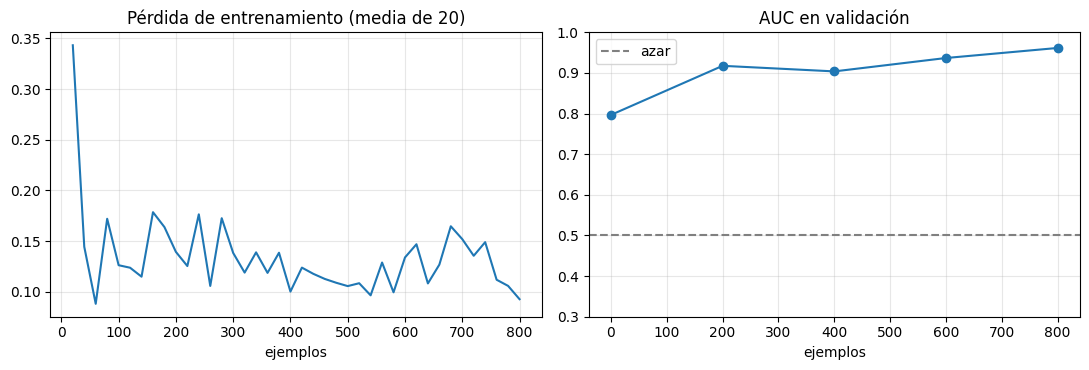

In [ ]:
h = pd.DataFrame(historial)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
if "train" in h:
    d = h.dropna(subset=["train"]); a1.plot(d["ejemplo"], d["train"])
a1.set_title("Pérdida de entrenamiento (media de 20)"); a1.set_xlabel("ejemplos"); a1.grid(alpha=.3)
if "auc_val" in h:
    d = h.dropna(subset=["auc_val"]); a2.plot(d["ejemplo"], d["auc_val"], "o-")
a2.axhline(0.5, ls="--", c="gray", label="azar"); a2.set_ylim(0.3, 1.0)
a2.set_title("AUC en validación"); a2.set_xlabel("ejemplos"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. Evaluación en test: base vs LoRA, mismas ventanas recortadas

Para cada modelo:
1. **P(sí)** en todas las ventanas → **AUC**.
2. **Umbral** elegido en **validación**: el que maximiza (recall + especificidad) / 2. Así no se "hace trampa" ajustándolo con test.
3. **Respuesta generada** (greedy) → tipo y segundo, y también la decisión "tal cual" del modelo.

In [ ]:
PROB_FALLIDAS = []   # ventanas donde fp16 se desbordó en todos los intentos


def prob_incidente(v):
    """P(incidente = true). Si fp16 se desborda, reintenta sin autocast y luego con la mitad de frames;
    si todo falla, devuelve 0.5 (no sabe) y lo anota."""
    intentos = [(v, True), (v, False)]
    if len(v["frames"]) >= 4:
        mitad = v.copy()
        mitad["frames"] = v["frames"][::2][: (len(v["frames"][::2]) // 2) * 2]
        mitad["fps_ef"] = v["fps_ef"] / 2
        intentos.append((mitad, False))
    for vv, con_autocast in intentos:
        usuario = mensaje_usuario(vv)
        texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True) + PREFIJO
        ent = procesar(texto, usuario, vv["fps_ef"]).to(modelo.device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=con_autocast):
            logits = modelo(**ent).logits[0, -1, [TOK_SI, TOK_NO]].float()
        if torch.isfinite(logits).all():
            return torch.softmax(logits, -1)[0].item()
    PROB_FALLIDAS.append(v["video"])
    return 0.5

In [ ]:
def umbral_de(df):
    _, p = auc_de(df)
    y = (df["clase"] == "positiva").astype(int).values
    fpr, tpr, umbrales = roc_curve(y, p)
    return float(umbrales[np.argmax(tpr - fpr)])


def conteos(y, pred):
    vp, fn = int((y & pred).sum()), int((y & ~pred).sum())
    fp, vn = int((~y & pred).sum()), int((~y & ~pred).sum())
    return vp, fn, fp, vn


def evaluar(nombre):
    modelo.eval(); modelo.config.use_cache = True
    umbral = umbral_de(VAL)
    filas = []
    for i, v in TEST.iterrows():
        r = juzgar(v)
        r["p_si"] = prob_incidente(v)
        filas.append({**v.drop(labels=["frames", "contexto"], errors="ignore").to_dict(),
                      **{(f"pred_{k}" if k in ("incidente", "tipo", "segundo_aprox") else k): x for k, x in r.items()}})
        if (i + 1) % 20 == 0:
            print(f"  {nombre}: {i+1}/{len(TEST)}", flush=True)
    res = pd.DataFrame(filas)
    res.to_csv(os.path.join(DIR_RESULTADOS, f"test_roi_{nombre}_{HUELLA}.csv"), index=False)

    y = (res["clase"] == "positiva").values
    out = {"AUC": roc_auc_score(y.astype(int), res["p_si"]), "umbral (de val)": umbral}
    for etiqueta, pred in (("generada", res["pred_incidente"].fillna(False).astype(bool).values),
                           ("con umbral", (res["p_si"] >= umbral).values)):
        vp, fn, fp, vn = conteos(y, pred)
        out[f"choques detectados ({etiqueta})"] = f"{vp}/{vp+fn}"
        out[f"falsas alarmas ({etiqueta})"] = f"{fp}/{fp+vn}"
        out[f"precision ({etiqueta})"] = f"{vp/(vp+fp):.0%}" if vp + fp else "—"
    det = res[y & res["pred_incidente"].fillna(False).astype(bool).values]
    out["tipo correcto"] = f"{(det['pred_tipo'] == det['tipo_real'].map(tipo_json)).mean():.0%}" if len(det) else "—"
    con_t = det[det["pred_segundo_aprox"].notna()]
    err = (con_t["pred_segundo_aprox"] - con_t["t_rel"]).abs()
    out["segundo dentro de ±2 s"] = f"{(err <= 2).mean():.0%}" if len(err) else "—"
    out["JSON válido"] = f"{(res['formato'] == 'ok').mean():.0%}"
    out["latencia generación (s)"] = f"{res['segundos'].median():.1f}"
    return res, out


with modelo.disable_adapter():
    res_base, m_base = evaluar("base")
res_lora, m_lora = evaluar("lora")

tabla = pd.DataFrame({"Base 4 bits + ROI": m_base, "LoRA + ROI": m_lora})
for col in tabla:
    tabla[col] = tabla[col].map(lambda x: f"{x:.3f}" if isinstance(x, float) else x)
print(tabla.to_string())
tabla.to_csv(os.path.join(DIR_RESULTADOS, f"comparacion_roi_{HUELLA}.csv"))
print("\nReferencia R2b (imagen completa): falsas alarmas 29/30 base, 28/30 LoRA · detectados 30/30 y 28/30 · tipo 47 % y 57 %")

  base: 20/60
  base: 40/60
  base: 60/60
  lora: 20/60
  lora: 40/60
  lora: 60/60
                                Base 4 bits + ROI LoRA + ROI
AUC                                         0.648      0.753
umbral (de val)                             0.676      0.461
choques detectados (generada)               28/30      26/30
falsas alarmas (generada)                   26/30      12/30
precision (generada)                          52%        68%
choques detectados (con umbral)             22/30      27/30
falsas alarmas (con umbral)                 15/30      16/30
precision (con umbral)                        59%        63%
tipo correcto                                 50%        65%
segundo dentro de ±2 s                        61%        62%
JSON válido                                  100%       100%
latencia generación (s)                       5.6        6.7

Referencia R2b (imagen completa): falsas alarmas 29/30 base, 28/30 LoRA · detectados 30/30 y 28/30 · tipo 47 % y 57 %


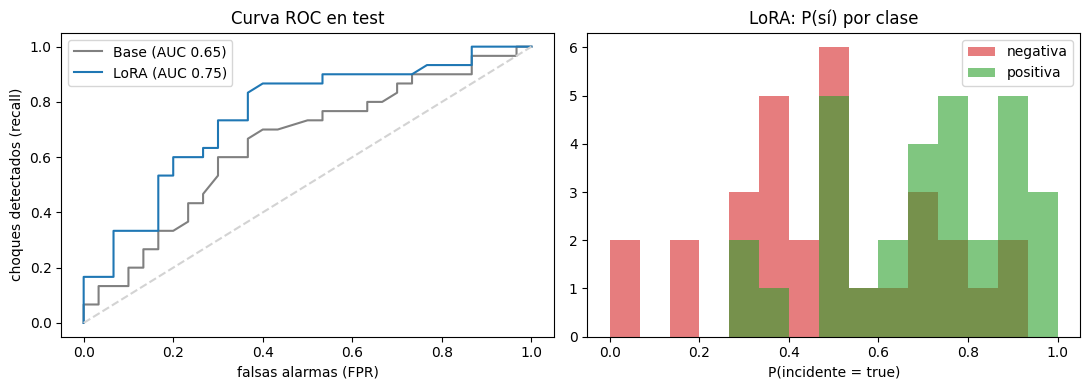

Tipo (LoRA, positivas detectadas):


pred_tipo,en_t,roce_lateral,un_vehiculo,All
tipo_esperado,,,,
alcance,0,0,2,2
en_t,11,0,3,14
frontal,1,0,0,1
roce_lateral,2,0,0,2
un_vehiculo,0,1,6,7
All,14,1,11,26


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for res, nombre, c in ((res_base, "Base", "gray"), (res_lora, "LoRA", "C0")):
    y = (res["clase"] == "positiva").astype(int)
    fpr, tpr, _ = roc_curve(y, res["p_si"])
    ejes[0].plot(fpr, tpr, c=c, label=f"{nombre} (AUC {roc_auc_score(y, res['p_si']):.2f})")
ejes[0].plot([0, 1], [0, 1], "--", c="lightgray"); ejes[0].set_xlabel("falsas alarmas (FPR)")
ejes[0].set_ylabel("choques detectados (recall)"); ejes[0].set_title("Curva ROC en test"); ejes[0].legend()
for clase, c in (("negativa", "C3"), ("positiva", "C2")):
    ejes[1].hist(res_lora[res_lora["clase"] == clase]["p_si"], bins=15, range=(0, 1), alpha=.6, color=c, label=clase)
ejes[1].set_title("LoRA: P(sí) por clase"); ejes[1].set_xlabel("P(incidente = true)"); ejes[1].legend()
plt.tight_layout(); plt.show()

det = res_lora[(res_lora["clase"] == "positiva") & res_lora["pred_incidente"].fillna(False).astype(bool)].copy()
det["tipo_esperado"] = det["tipo_real"].map(tipo_json)
print("Tipo (LoRA, positivas detectadas):")
display(pd.crosstab(det["tipo_esperado"], det["pred_tipo"], margins=True))

## Cómo leer los resultados

- **AUC** es el número principal. 0.5 = azar, 0.7 = algo aprende, 0.8+ = distingue bien. Compara: base con ROI (antes de entrenar) → LoRA con ROI.
- **Histograma de P(sí):** si las barras rojas (negativas) se van a la izquierda y las verdes (positivas) a la derecha, el modelo está separando las clases.
- **Con umbral vs generada:** la respuesta generada usa un umbral implícito de 0.5. Si el modelo es "optimista", el umbral de validación puede bajar mucho las falsas alarmas sin reentrenar.
- **Margen de error:** con 30 negativas, cada falsa alarma vale 3.3 puntos. Diferencias menores a ~15 puntos pueden ser azar.
- **Para el reporte:** el ROI viene de la anotación (equivale a un paso 2 perfecto). En el sistema real, el ROI lo daría el tracker y tendría errores; eso se mide en el prototipo de tiempo real.